In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [2]:
# timestamp issues (DST, UTC weather file, duplicate load rows) are fixed upstream by clean_timestamps.py:
# every file is local market time, exactly 24 rows/day, and merges 1:1 on `timestamp`
load = pd.read_csv('clean/load.csv', parse_dates=['timestamp'])
prices = pd.read_csv('clean/prices.csv', parse_dates=['timestamp'])
weather = pd.read_csv('clean/renewables_weather.csv', parse_dates=['timestamp'])

load

,timestamp,load_actual_mw,load_forecast_mw,load_actual_gw,dst_adjusted
0,2021-01-01 00:00:00,40341.0,40341.0,40.341,False
1,2021-01-01 01:00:00,39895.0,39685.0,39.895,False
2,2021-01-01 02:00:00,39250.0,38683.0,39.250,False
3,2021-01-01 03:00:00,39283.0,38875.0,39.283,False
4,2021-01-01 04:00:00,40240.0,39599.0,40.240,False
...,...,...,...,...,...
26275,2023-12-31 19:00:00,48152.0,47427.0,48.152,False
26276,2023-12-31 20:00:00,46777.0,46626.0,46.777,False
26277,2023-12-31 21:00:00,44574.0,44438.0,44.574,False
26278,2023-12-31 22:00:00,41313.0,41007.0,41.313,False


In [3]:
prices['date'] = prices['timestamp'].dt.normalize()
prices

,timestamp,price_eur_mwh,daily_avg_price,dst_adjusted,date
0,2021-01-01 00:00:00,44.98,47.91,False,2021-01-01
1,2021-01-01 01:00:00,40.82,47.91,False,2021-01-01
2,2021-01-01 02:00:00,38.19,47.91,False,2021-01-01
3,2021-01-01 03:00:00,33.17,47.91,False,2021-01-01
4,2021-01-01 04:00:00,31.69,47.91,False,2021-01-01
...,...,...,...,...,...
26275,2023-12-31 19:00:00,105.78,84.32,False,2023-12-31
26276,2023-12-31 20:00:00,106.10,84.32,False,2023-12-31
26277,2023-12-31 21:00:00,99.21,84.32,False,2023-12-31
26278,2023-12-31 22:00:00,87.20,84.32,False,2023-12-31


In [4]:
weather

,timestamp,temp_c,temp_f,wind_actual_mw,wind_forecast_mw,solar_actual_mw,solar_forecast_mw,dst_adjusted
0,2021-01-01 00:00:00,-2.5,27.5,9799.0,9799.0,0.0,0.0,False
1,2021-01-01 01:00:00,-3.8,25.2,10193.0,9370.0,0.0,0.0,False
2,2021-01-01 02:00:00,-3.7,25.3,10966.0,10324.0,0.0,0.0,False
3,2021-01-01 03:00:00,-3.3,26.1,10512.0,9784.0,0.0,0.0,False
4,2021-01-01 04:00:00,-4.3,24.3,12077.0,10656.0,0.0,0.0,False
...,...,...,...,...,...,...,...,...
26275,2023-12-31 19:00:00,4.9,40.8,2575.0,2241.0,0.0,0.0,False
26276,2023-12-31 20:00:00,3.6,38.5,2471.0,2274.0,0.0,0.0,False
26277,2023-12-31 21:00:00,3.0,37.4,1989.0,1829.0,0.0,0.0,False
26278,2023-12-31 22:00:00,1.7,35.1,1874.0,1743.0,0.0,0.0,False


Timestamp fixes (done in `clean_timestamps.py`, see its docstring):
- `renewables_weather.csv` was in UTC; converted to local market time.
- `load.csv` had 140 exact duplicate rows; dropped.
- DST: on spring-forward days the missing 02:00 is the mean of 01:00 and 03:00; on fall-back days the two 02:00 hours are averaged. These rows have `dst_adjusted = True`.
- Not fixed: the weather outage 2022-02-07 01:00 to 2022-02-12 06:00 (126 h) stays as NaN rows.

In [5]:
prices['price_eur_mwh'].describe()

count    26280.000000
mean       135.736510
std        297.696211
min      -9999.000000
25%         79.287500
50%        116.120000
75%        187.032500
max       3000.000000
Name: price_eur_mwh, dtype: float64

In [6]:
prices[prices['price_eur_mwh'] < -1000]

,timestamp,price_eur_mwh,daily_avg_price,dst_adjusted,date
10226,2022-03-03 02:00:00,-9999.0,211.29,False,2022-03-03
10555,2022-03-16 19:00:00,-9999.0,281.61,False,2022-03-16
11199,2022-04-12 15:00:00,-9999.0,298.30,False,2022-04-12
11304,2022-04-17 00:00:00,-9999.0,128.54,False,2022-04-17
11566,2022-04-27 22:00:00,-9999.0,213.11,False,2022-04-27
11688,2022-05-03 00:00:00,-9999.0,263.31,False,2022-05-03
11814,2022-05-08 06:00:00,-9999.0,36.93,False,2022-05-08
11987,2022-05-15 11:00:00,-9999.0,131.78,False,2022-05-15
12060,2022-05-18 12:00:00,-9999.0,201.00,False,2022-05-18
13924,2022-08-04 04:00:00,-9999.0,196.92,False,2022-08-04


The -9999 price in the data looks like a placeholder for missing data, because it's largely deviating from the daily_avg_price and appears with no clear patterns, so we fill these values as na.

In [7]:
prices.loc[prices['price_eur_mwh'] == -9999, 'price_eur_mwh'] = np.nan

In [8]:
prices[prices['price_eur_mwh'] > 1000]

,timestamp,price_eur_mwh,daily_avg_price,dst_adjusted,date
163,2021-01-07 19:00:00,2562.49,220.97,False,2021-01-07
322,2021-01-14 10:00:00,1548.80,105.11,False,2021-01-14
949,2021-02-09 13:00:00,1395.06,193.35,False,2021-02-09
5289,2021-08-09 09:00:00,1288.92,131.79,False,2021-08-09
7570,2021-11-12 10:00:00,1267.22,247.24,False,2021-11-12
...,...,...,...,...,...
25963,2023-12-18 19:00:00,1931.01,246.05,False,2023-12-18
25977,2023-12-19 09:00:00,1252.18,151.72,False,2023-12-19
26051,2023-12-22 11:00:00,1586.37,173.89,False,2023-12-22
26199,2023-12-28 15:00:00,1451.38,177.07,False,2023-12-28


In [9]:
prices[prices['price_eur_mwh'] == 3000]

,timestamp,price_eur_mwh,daily_avg_price,dst_adjusted,date
9399,2022-01-27 15:00:00,3000.0,467.64,False,2022-01-27
10187,2022-03-01 11:00:00,3000.0,445.30,False,2022-03-01
22016,2023-07-07 08:00:00,3000.0,202.55,False,2023-07-07
23152,2023-08-23 16:00:00,3000.0,280.10,False,2023-08-23
25359,2023-11-23 15:00:00,3000.0,396.37,False,2023-11-23


There are also some positive outliers in the data which is also significantly larger than the daily_avg_price.

Since there's a daily_avg_price, we can use this to verify about the correctness of these price data.

In [10]:
groups = prices.groupby(pd.Grouper(key='timestamp', freq='D'))

print(f"All daily_avg_price within a day is the same: {(groups['daily_avg_price'].nunique() == 1).all()}")

agg_price = groups.agg(
    avg_price = pd.NamedAgg(column='price_eur_mwh', aggfunc='mean'),
    std_price = pd.NamedAgg(column='price_eur_mwh', aggfunc='std'),
    daily_avg_price = pd.NamedAgg(column='daily_avg_price', aggfunc='last'),
    n_valid = pd.NamedAgg(column='price_eur_mwh', aggfunc='count'),
    n_rows = pd.NamedAgg(column='price_eur_mwh', aggfunc='size'),
    dst_day = pd.NamedAgg(column='dst_adjusted', aggfunc='any'),
)
agg_price['diff'] = agg_price['avg_price'] - agg_price['daily_avg_price']
# DST days are excluded: the vendor average covers the real 23/25 hours, our cleaned day has 24 rows
valid_days = (agg_price['n_valid'] == agg_price['n_rows']) & ~agg_price['dst_day']
print('Max diff for all valid days: ', agg_price.loc[valid_days, 'diff'].abs().max())
print('Number of days with missing prices: ', (agg_price['n_valid'] < agg_price['n_rows']).sum())

All daily_avg_price within a day is the same: True
Max diff for all valid days:  0.005000000000023874
Number of days with missing prices:  18


In [11]:
agg_price['missing_price'] = agg_price['daily_avg_price'] * agg_price['n_rows'] - agg_price['avg_price'] * agg_price['n_valid']
prices['price_eur_mwh'] = prices['price_eur_mwh'].fillna(prices['date'].map(agg_price['missing_price']))
prices.isnull().sum()

timestamp          0
price_eur_mwh      0
daily_avg_price    0
dst_adjusted       0
date               0
dtype: int64

(array([ 93., 215., 143., 112.,  91.,  95.,  49.,  33.,  21.,  21.,  20.,
         13.,  10.,   7.,  11.,  13.,  11.,  11.,   6.,  10.,   4.,   4.,
          6.,   3.,   5.,   1.,   4.,   5.,   3.,   4.,   7.,   7.,   3.,
          3.,   2.,   2.,   5.,   1.,   0.,   3.,   1.,   3.,   4.,   3.,
          3.,   1.,   0.,   1.,   1.,   0.,   1.,   0.,   1.,   2.,   0.,
          1.,   0.,   0.,   0.,   3.,   1.,   1.,   0.,   0.,   2.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   1.,   0.,   0.,
          0.,   0.,   1.,   0.,   0.,   1.,   2.,   1.,   0.,   0.,   1.,
          0.,   0.,   1.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          1.]),
 array([  5.89514205,  12.9332279 ,  19.97131375,  27.0093996 ,
         34.04748545,  41.0855713 ,  48.12365715,  55.161743  ,
         62.19982885,  69.2379147 ,  76.27600055,  83.3140864 ,
         90.35217225,  97.3902581 , 104.42834395, 111.4664298 ,
        118.50451565, 125.5426015 , 132.58068735, 139.6187732 

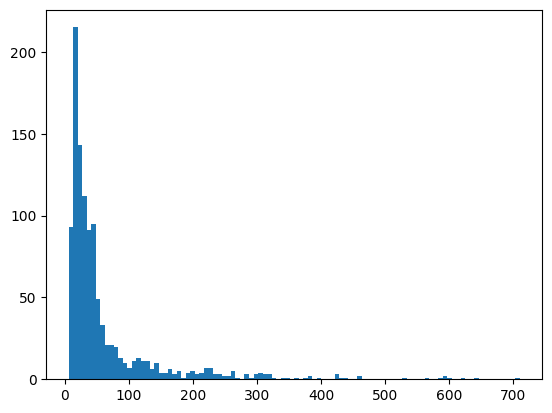

In [12]:
plt.hist(agg_price['std_price'], bins=100)

This is probably due to time zone change, where daily_avg_price is calculated on 24 hours, but there're only 23 rows in this day. For other data, there's not an explicit reason for them to be missing, and since the given daily_avg_price doesn't deviate from our calculated average price by much, data correctness can be trusted. We don't fill them with the daily_avg_price, because it's observed that within the day, the deviation of prices could be very large, so we just model them as missing value for now.

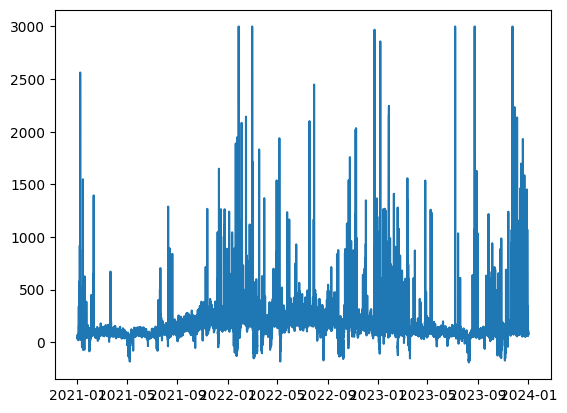

In [13]:
plt.plot(prices['timestamp'], prices['price_eur_mwh'])

Because there're negative prices in this time series, so log transformation doesn't work here. And these negative prices doesn't look like data issues, because the daily average price is also negative, so they should not be dropped. 

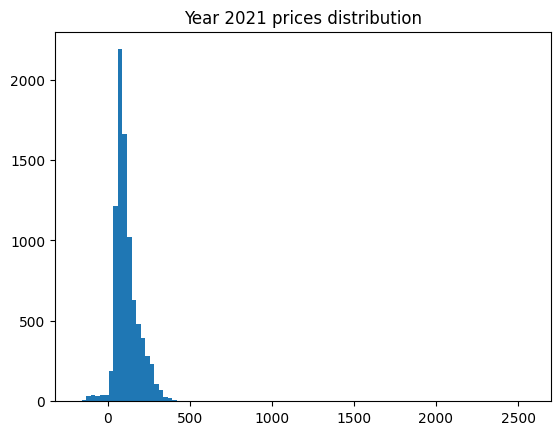

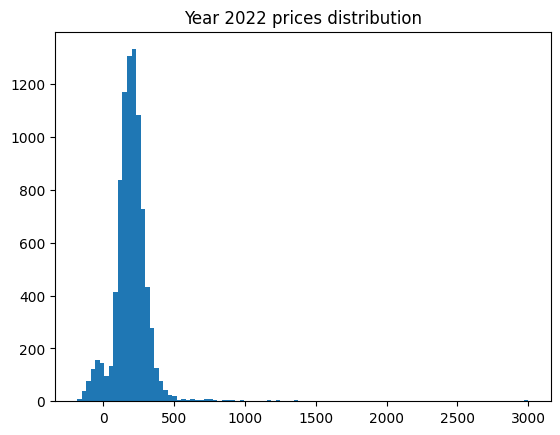

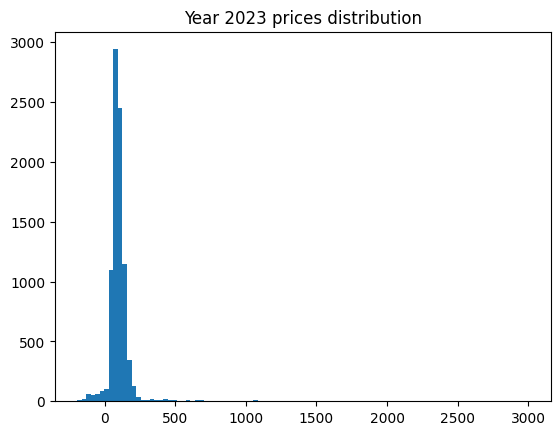

In [14]:
for year in range(2021, 2024):
    yearly_prices = prices[prices['timestamp'].dt.year == year]
    plt.hist(yearly_prices['price_eur_mwh'], bins=100)
    plt.title(f"Year {year} prices distribution")
    plt.show()

However this data is still quite right-skewed, so we should use some transformation to make it more normally distributed. Because of negative values, we can use the Yeo-Johnson transformation. We first use z-score to squeeze these data into a more comparable scale, then apply the Yeo-Johnson.

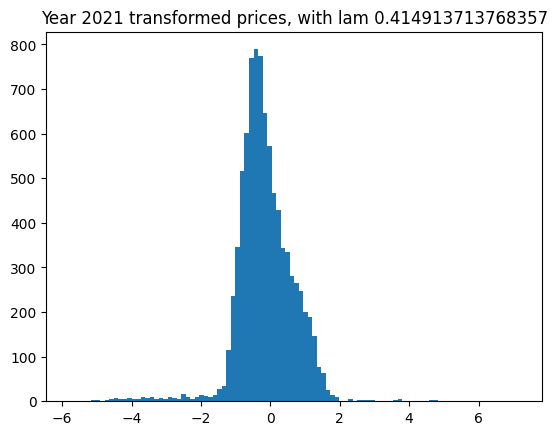

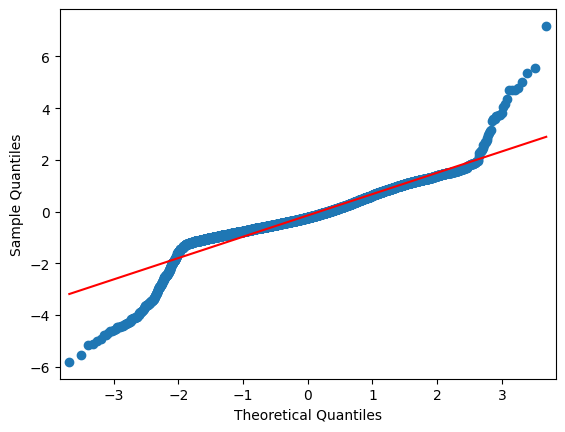

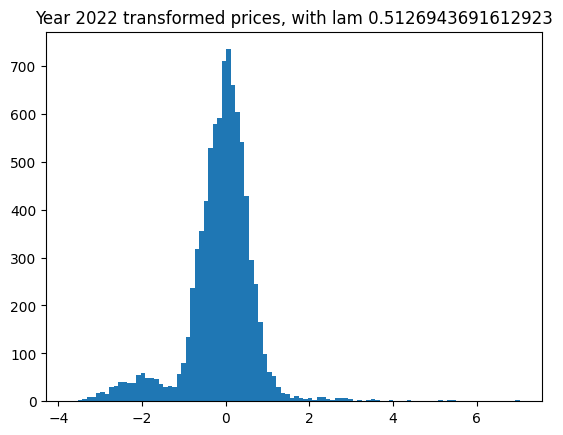

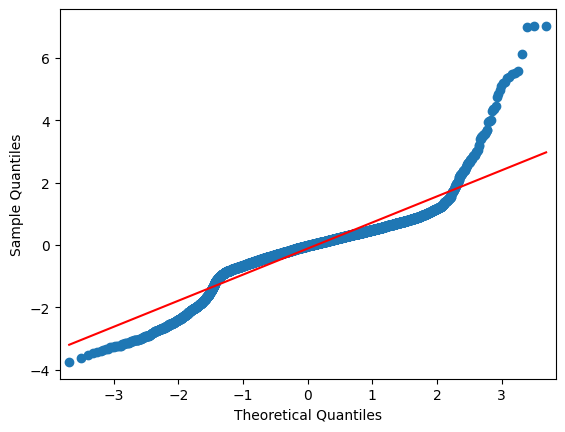

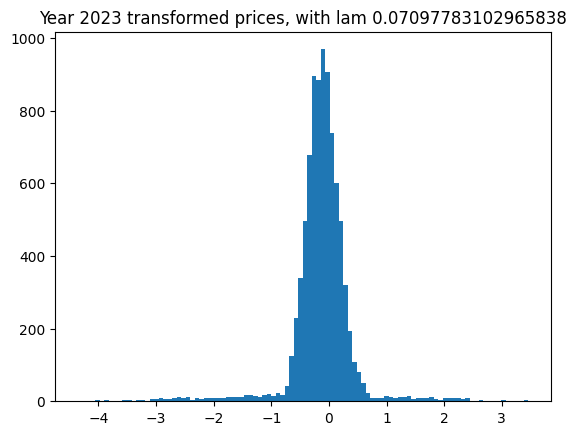

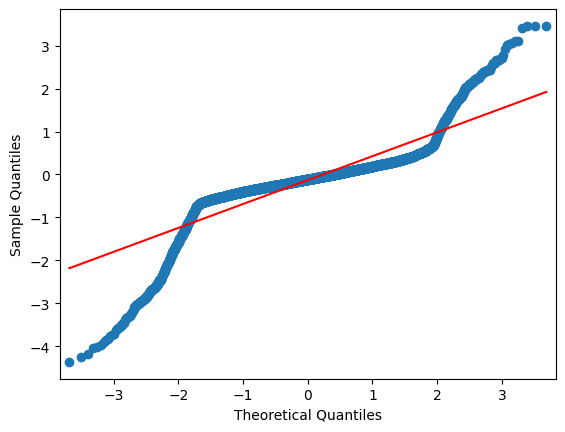

In [15]:
from scipy import stats
import statsmodels.api as sm

for year in range(2021, 2024):
    yearly_prices = prices.loc[prices['timestamp'].dt.year == year, 'price_eur_mwh']
    yearly_z_scores = (yearly_prices - yearly_prices.mean()) / yearly_prices.std()
    transformed_price, lam = stats.yeojohnson(yearly_z_scores.dropna())
    plt.hist(transformed_price, bins=100)
    plt.title(f"Year {year} transformed prices, with lam {lam}")
    sm.qqplot(transformed_price, line='s')
    plt.show()

In [16]:
def rolling_robust_stats(prices):
    by_day = prices.groupby('date')['price_eur_mwh'].apply(np.array)
    result = {}
    for i in range(28, len(by_day)):
        dt = np.concatenate(by_day.iloc[i-28:i].values)
        med = np.median(dt)
        result[by_day.index[i]] = [med, 1.4826 * np.median(np.abs(dt - med))]
    return pd.DataFrame.from_dict(result, orient='index', columns=['price_med_28d', 'price_mad_28d'])

In [17]:
prices

,timestamp,price_eur_mwh,daily_avg_price,dst_adjusted,date
0,2021-01-01 00:00:00,44.98,47.91,False,2021-01-01
1,2021-01-01 01:00:00,40.82,47.91,False,2021-01-01
2,2021-01-01 02:00:00,38.19,47.91,False,2021-01-01
3,2021-01-01 03:00:00,33.17,47.91,False,2021-01-01
4,2021-01-01 04:00:00,31.69,47.91,False,2021-01-01
...,...,...,...,...,...
26275,2023-12-31 19:00:00,105.78,84.32,False,2023-12-31
26276,2023-12-31 20:00:00,106.10,84.32,False,2023-12-31
26277,2023-12-31 21:00:00,99.21,84.32,False,2023-12-31
26278,2023-12-31 22:00:00,87.20,84.32,False,2023-12-31


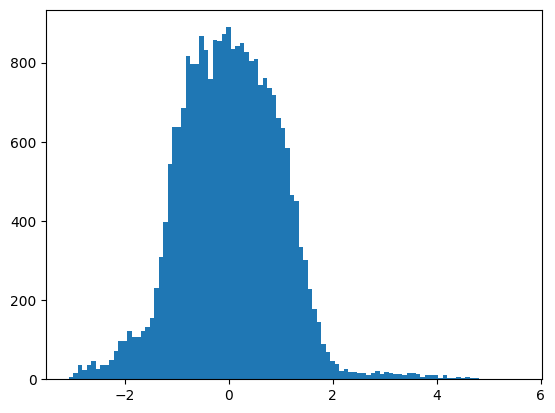

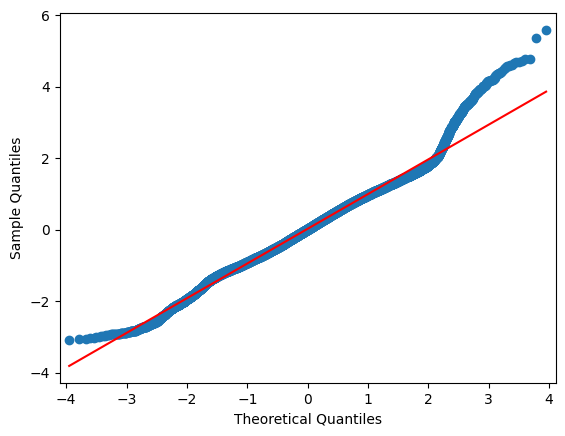

In [18]:
prices = pd.merge(prices, rolling_robust_stats(prices), left_on='date', right_index=True, how='left')
prices['z_28d'] = (prices['price_eur_mwh'] - prices['price_med_28d']) / prices['price_mad_28d']

plt.hist(np.arcsinh(prices['z_28d']).dropna(), bins=100)
sm.qqplot(np.arcsinh(prices['z_28d']).dropna(), line='s')
plt.show()

In [19]:
df = pd.merge(prices, load, on=['timestamp', 'dst_adjusted'], how='left')
df = pd.merge(df, weather, on=['timestamp', 'dst_adjusted'], how='left')
df

,timestamp,price_eur_mwh,daily_avg_price,dst_adjusted,date,price_med_28d,price_mad_28d,z_28d,load_actual_mw,load_forecast_mw,load_actual_gw,temp_c,temp_f,wind_actual_mw,wind_forecast_mw,solar_actual_mw,solar_forecast_mw
0,2021-01-01 00:00:00,44.98,47.91,False,2021-01-01,NaN,NaN,NaN,40341.0,40341.0,40.341,-2.5,27.5,9799.0,9799.0,0.0,0.0
1,2021-01-01 01:00:00,40.82,47.91,False,2021-01-01,NaN,NaN,NaN,39895.0,39685.0,39.895,-3.8,25.2,10193.0,9370.0,0.0,0.0
2,2021-01-01 02:00:00,38.19,47.91,False,2021-01-01,NaN,NaN,NaN,39250.0,38683.0,39.250,-3.7,25.3,10966.0,10324.0,0.0,0.0
3,2021-01-01 03:00:00,33.17,47.91,False,2021-01-01,NaN,NaN,NaN,39283.0,38875.0,39.283,-3.3,26.1,10512.0,9784.0,0.0,0.0
4,2021-01-01 04:00:00,31.69,47.91,False,2021-01-01,NaN,NaN,NaN,40240.0,39599.0,40.240,-4.3,24.3,12077.0,10656.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26275,2023-12-31 19:00:00,105.78,84.32,False,2023-12-31,102.29,27.598599,0.126456,48152.0,47427.0,48.152,4.9,40.8,2575.0,2241.0,0.0,0.0
26276,2023-12-31 20:00:00,106.10,84.32,False,2023-12-31,102.29,27.598599,0.138050,46777.0,46626.0,46.777,3.6,38.5,2471.0,2274.0,0.0,0.0
26277,2023-12-31 21:00:00,99.21,84.32,False,2023-12-31,102.29,27.598599,-0.111600,44574.0,44438.0,44.574,3.0,37.4,1989.0,1829.0,0.0,0.0
26278,2023-12-31 22:00:00,87.20,84.32,False,2023-12-31,102.29,27.598599,-0.546767,41313.0,41007.0,41.313,1.7,35.1,1874.0,1743.0,0.0,0.0


## A2

In [20]:
load['ratio'] = load['load_actual_mw'] / load['load_actual_gw']
load['ratio'].describe()

count    26280.000000
mean       991.095890
std         89.077031
min        100.000000
25%       1000.000000
50%       1000.000000
75%       1000.000000
max       1000.000000
Name: ratio, dtype: float64

In [21]:
load[load['ratio'] < 900]

,timestamp,load_actual_mw,load_forecast_mw,load_actual_gw,dst_adjusted,ratio
115,2021-01-05 19:00:00,65480.0,65648.0,654.80,False,100.0
190,2021-01-08 22:00:00,50477.0,50680.0,504.77,False,100.0
251,2021-01-11 11:00:00,63885.0,65844.0,638.85,False,100.0
474,2021-01-20 18:00:00,60685.0,59938.0,606.85,False,100.0
596,2021-01-25 20:00:00,61414.0,62879.0,614.14,False,100.0
...,...,...,...,...,...,...
25873,2023-12-15 01:00:00,44425.0,43163.0,444.25,False,100.0
25940,2023-12-17 20:00:00,48032.0,48808.0,480.32,False,100.0
25987,2023-12-19 19:00:00,59743.0,61623.0,597.43,False,100.0
26169,2023-12-27 09:00:00,57907.0,58542.0,579.07,False,100.0


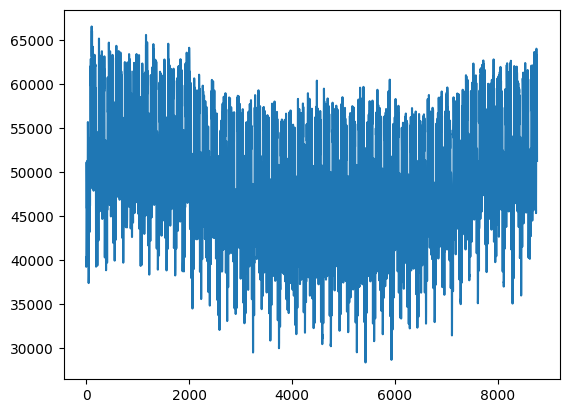

In [22]:
load_2021 = load[load['timestamp'].dt.year == 2021]
plt.plot(load_2021['load_actual_mw'])

In [23]:
load['load_actual_gw'] = load['load_actual_mw'] / 1000

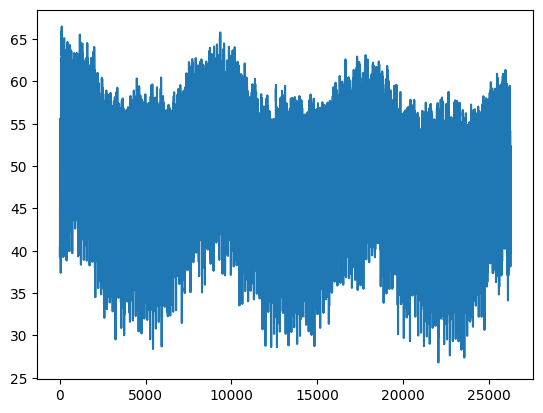

In [24]:
plt.plot(load['load_actual_gw'])

In [25]:
load_actual_daily_mw = load.groupby(pd.Grouper(key='timestamp', freq='D'))['load_actual_mw'].mean().rename('load_actual_daily_mw')
load_actual_daily_mw

timestamp
2021-01-01    45994.875000
2021-01-02    49884.958333
2021-01-03    47197.083333
2021-01-04    56825.958333
2021-01-05    59582.041667
                  ...     
2023-12-27    52790.250000
2023-12-28    53256.458333
2023-12-29    53434.791667
2023-12-30    48448.083333
2023-12-31    45215.500000
Freq: D, Name: load_actual_daily_mw, Length: 1095, dtype: float64

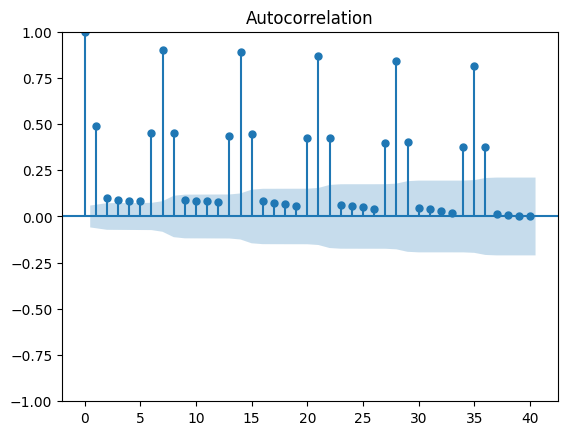

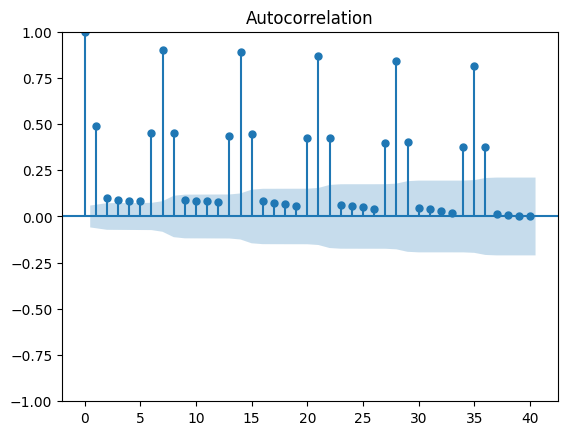

In [26]:
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(load_actual_daily_mw, lags=40)

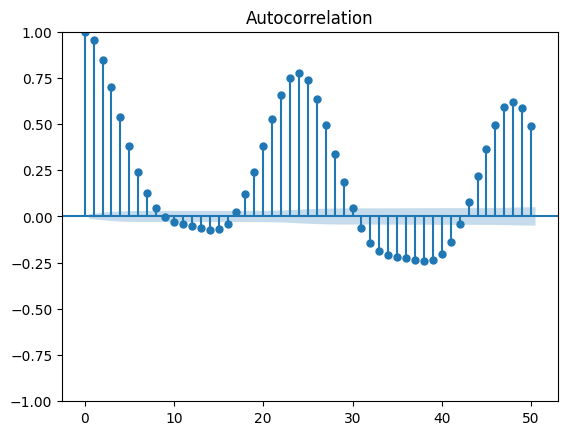

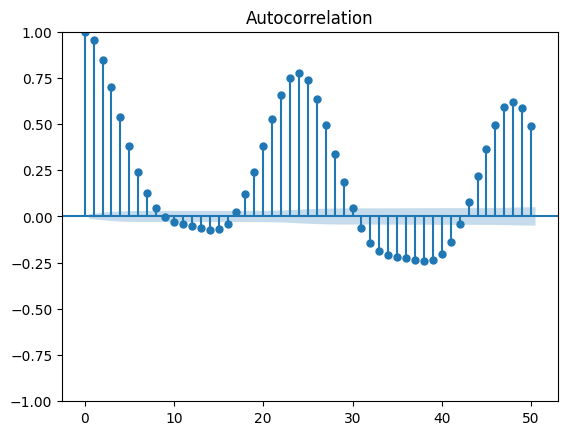

In [27]:
plot_acf(load['load_actual_mw'], lags=50)

In [28]:
load['date'] = load['timestamp'].dt.normalize()
load = pd.merge(load, load_actual_daily_mw, left_on='date', right_index=True)

<Axes: title={'center': 'load_actual_daily_mw'}, xlabel='day_of_week'>

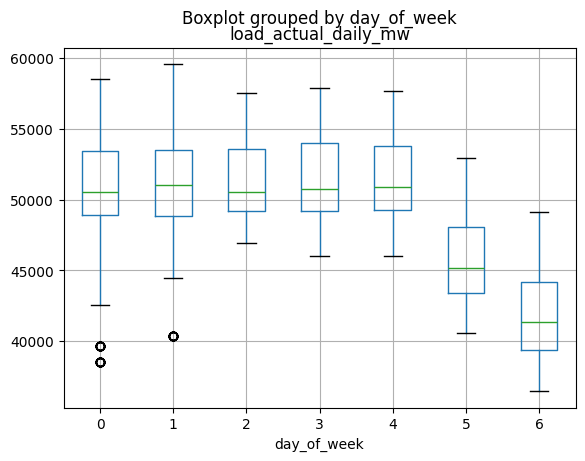

In [29]:
load['day_of_week'] = load['date'].dt.day_of_week

load.boxplot(column='load_actual_daily_mw', by='day_of_week')

<Axes: xlabel='timestamp'>

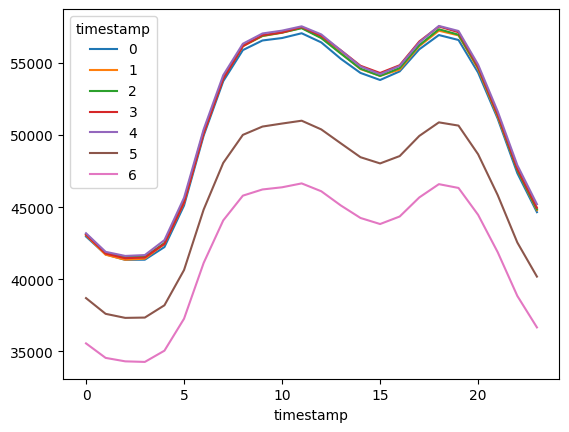

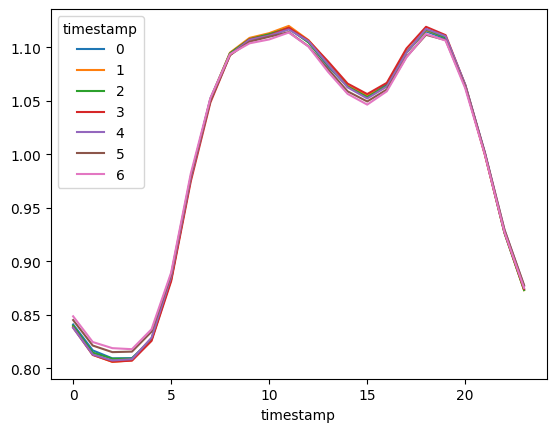

In [30]:
prof = (load.groupby([load['timestamp'].dt.dayofweek, load['timestamp'].dt.hour])['load_actual_mw']
            .mean().unstack(0))          # rows = hour 0..23, columns = weekday 0..6
prof.plot()                               # one line per weekday
(prof / prof.mean()).plot()               # divide out each day's level -> compares *shape* only

In [31]:
trend = load_actual_daily_mw.rolling(14, min_periods=1).mean().rename('trend')
load = pd.merge(load, trend, left_on='date', right_index=True, how='left')
load['detrend'] = load['load_actual_mw'] - load['trend']

In [32]:
load

,timestamp,load_actual_mw,load_forecast_mw,load_actual_gw,dst_adjusted,ratio,date,load_actual_daily_mw,day_of_week,trend,detrend
0,2021-01-01 00:00:00,40341.0,40341.0,40.341,False,1000.0,2021-01-01,45994.875,4,45994.875,-5653.875
1,2021-01-01 01:00:00,39895.0,39685.0,39.895,False,1000.0,2021-01-01,45994.875,4,45994.875,-6099.875
2,2021-01-01 02:00:00,39250.0,38683.0,39.250,False,1000.0,2021-01-01,45994.875,4,45994.875,-6744.875
3,2021-01-01 03:00:00,39283.0,38875.0,39.283,False,1000.0,2021-01-01,45994.875,4,45994.875,-6711.875
4,2021-01-01 04:00:00,40240.0,39599.0,40.240,False,1000.0,2021-01-01,45994.875,4,45994.875,-5754.875
...,...,...,...,...,...,...,...,...,...,...,...
26275,2023-12-31 19:00:00,48152.0,47427.0,48.152,False,1000.0,2023-12-31,45215.500,6,50309.750,-2157.750
26276,2023-12-31 20:00:00,46777.0,46626.0,46.777,False,1000.0,2023-12-31,45215.500,6,50309.750,-3532.750
26277,2023-12-31 21:00:00,44574.0,44438.0,44.574,False,1000.0,2023-12-31,45215.500,6,50309.750,-5735.750
26278,2023-12-31 22:00:00,41313.0,41007.0,41.313,False,1000.0,2023-12-31,45215.500,6,50309.750,-8996.750


In [33]:
daily_detrend = load_actual_daily_mw - trend
seasonality = daily_detrend.groupby(daily_detrend.index.day_of_week).rolling(5, min_periods=1).mean().reset_index(level=0, drop=True).dropna().rename('seasonality')
load = pd.merge(load, seasonality, left_on='date', right_index=True)
load

,timestamp,load_actual_mw,load_forecast_mw,load_actual_gw,dst_adjusted,ratio,date,load_actual_daily_mw,day_of_week,trend,detrend,seasonality
0,2021-01-01 00:00:00,40341.0,40341.0,40.341,False,1000.0,2021-01-01,45994.875,4,45994.875,-5653.875,0.000000
1,2021-01-01 01:00:00,39895.0,39685.0,39.895,False,1000.0,2021-01-01,45994.875,4,45994.875,-6099.875,0.000000
2,2021-01-01 02:00:00,39250.0,38683.0,39.250,False,1000.0,2021-01-01,45994.875,4,45994.875,-6744.875,0.000000
3,2021-01-01 03:00:00,39283.0,38875.0,39.283,False,1000.0,2021-01-01,45994.875,4,45994.875,-6711.875,0.000000
4,2021-01-01 04:00:00,40240.0,39599.0,40.240,False,1000.0,2021-01-01,45994.875,4,45994.875,-5754.875,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...
26275,2023-12-31 19:00:00,48152.0,47427.0,48.152,False,1000.0,2023-12-31,45215.500,6,50309.750,-2157.750,-6312.179167
26276,2023-12-31 20:00:00,46777.0,46626.0,46.777,False,1000.0,2023-12-31,45215.500,6,50309.750,-3532.750,-6312.179167
26277,2023-12-31 21:00:00,44574.0,44438.0,44.574,False,1000.0,2023-12-31,45215.500,6,50309.750,-5735.750,-6312.179167
26278,2023-12-31 22:00:00,41313.0,41007.0,41.313,False,1000.0,2023-12-31,45215.500,6,50309.750,-8996.750,-6312.179167


In [34]:
load['usable_trend'] = load['trend'].shift(24)
load['usable_seasonality'] = load['seasonality'].shift(168)

In [35]:
load['error'] = load['load_forecast_mw'] - load['load_actual_mw']
len(load[load['error'] == 0]), len(load[load['error'] == 0]) / len(load)

(522, 0.01986301369863014)

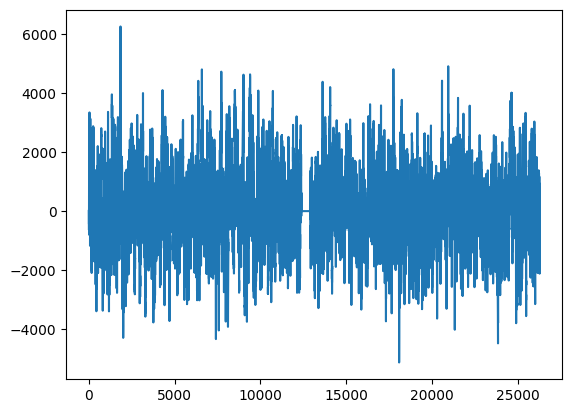

In [36]:
plt.plot(load['error'])

In [37]:
load['abs_error'] = load['error'].abs()
hour_abs_error = load.groupby(load['timestamp'].dt.hour)['abs_error'].mean()
hour_abs_error

timestamp
0      819.576256
1      786.922374
2      792.155708
3      811.227397
4      832.601826
5      873.737900
6      962.568950
7     1017.955251
8     1060.431963
9     1046.901370
10    1058.058447
11    1064.756164
12    1065.792694
13    1059.668493
14    1050.265753
15    1034.588128
16    1047.159817
17    1061.084932
18    1083.293151
19    1067.723288
20    1001.726027
21     945.368950
22     894.538813
23     846.472146
Name: abs_error, dtype: float64

## A3

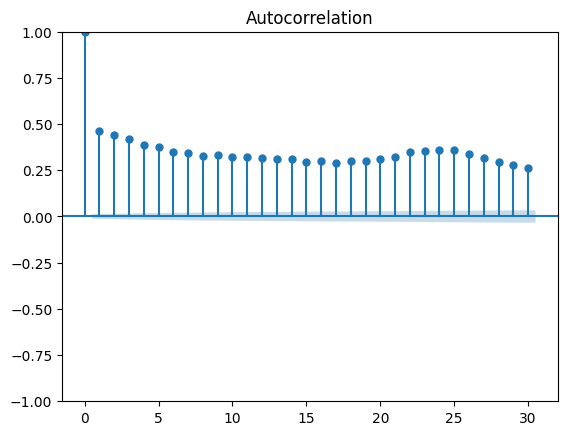

In [38]:
plot_acf(prices.set_index('timestamp')['price_eur_mwh'], lags=30)
plt.show()

## B

In [43]:
pd.DataFrame({'date': df['date'] - pd.DateOffset(days=1),
              'hour': df['timestamp'].dt.hour,
              'price': df['price_eur_mwh'],
              'z_28d': np.arcsinh(df['z_28d'])})

,date,hour,price,z_28d
0,2020-12-31,0,44.98,NaN
1,2020-12-31,1,40.82,NaN
2,2020-12-31,2,38.19,NaN
3,2020-12-31,3,33.17,NaN
4,2020-12-31,4,31.69,NaN
...,...,...,...,...
26275,2023-12-30,19,105.78,0.126121
26276,2023-12-30,20,106.10,0.137616
26277,2023-12-30,21,99.21,-0.111370
26278,2023-12-30,22,87.20,-0.522646


In [39]:
df = []
for date in prices['date'].unique():
    for hour in range(24):
        selected = prices.loc[(prices['date'] == date + pd.Timedelta(days=1)) & (prices['timestamp'].dt.hour == hour)]
        if len(selected) == 1:
            df.append([date, hour, selected['price_eur_mwh'].values[0], np.arcsinh(selected['z_28d']).values[0]])

In [40]:
df = pd.DataFrame(df, columns=['date', 'hour', 'price_tgt', 'adj_price_tgt'])
df

,date,hour,price_tgt,adj_price_tgt
0,2021-01-01,0,49.94,NaN
1,2021-01-01,1,57.58,NaN
2,2021-01-01,2,52.32,NaN
3,2021-01-01,3,51.04,NaN
4,2021-01-01,4,57.96,NaN
...,...,...,...,...
26251,2023-12-30,19,105.78,0.126121
26252,2023-12-30,20,106.10,0.137616
26253,2023-12-30,21,99.21,-0.111370
26254,2023-12-30,22,87.20,-0.522646


In [41]:
prices['hour'] = prices['timestamp'].dt.hour
df = pd.merge(df, prices, on=['date', 'hour'], how='left')

In [42]:
df = df.drop(columns=['timestamp', 'dst_adjusted'])
df = df.rename(columns={'price_eur_mwh': 'price_same_hour'})
df

,date,hour,price_tgt,adj_price_tgt,price_same_hour,daily_avg_price,price_med_28d,price_mad_28d,z_28d
0,2021-01-01,0,49.94,NaN,44.98,47.91,NaN,NaN,NaN
1,2021-01-01,1,57.58,NaN,40.82,47.91,NaN,NaN,NaN
2,2021-01-01,2,52.32,NaN,38.19,47.91,NaN,NaN,NaN
3,2021-01-01,3,51.04,NaN,33.17,47.91,NaN,NaN,NaN
4,2021-01-01,4,57.96,NaN,31.69,47.91,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
26251,2023-12-30,19,105.78,0.126121,102.28,101.26,103.07,27.783924,-0.028434
26252,2023-12-30,20,106.10,0.137616,91.23,101.26,103.07,27.783924,-0.426146
26253,2023-12-30,21,99.21,-0.111370,71.92,101.26,103.07,27.783924,-1.121152
26254,2023-12-30,22,87.20,-0.522646,73.74,101.26,103.07,27.783924,-1.055646


In [43]:
df['date_tgt'] = df['date'] + pd.Timedelta(days=1)
load['hour'] = load['timestamp'].dt.hour
df = pd.merge(df, load[['load_actual_mw', 'load_forecast_mw', 'date', 'hour', 'day_of_week']].rename(columns={'date': 'date_tgt'}), on=['date_tgt', 'hour'], 
              how='left')

In [44]:
weather['date'] = weather['timestamp'].dt.normalize()
weather['hour'] = weather['timestamp'].dt.hour
df = pd.merge(df, weather[['date', 'hour', 'wind_forecast_mw', 'solar_forecast_mw']].rename(columns={'date': 'date_tgt'}), on=['date_tgt', 'hour'],
              how='left')
df

,date,hour,price_tgt,adj_price_tgt,price_same_hour,daily_avg_price,price_med_28d,price_mad_28d,z_28d,date_tgt,load_actual_mw,load_forecast_mw,day_of_week,wind_forecast_mw,solar_forecast_mw
0,2021-01-01,0,49.94,NaN,44.98,47.91,NaN,NaN,NaN,2021-01-02,43708.0,44762.0,5,10621.0,0.0
1,2021-01-01,1,57.58,NaN,40.82,47.91,NaN,NaN,NaN,2021-01-02,42188.0,43493.0,5,8623.0,0.0
2,2021-01-01,2,52.32,NaN,38.19,47.91,NaN,NaN,NaN,2021-01-02,41981.0,43728.0,5,10335.0,0.0
3,2021-01-01,3,51.04,NaN,33.17,47.91,NaN,NaN,NaN,2021-01-02,41700.0,43927.0,5,10173.0,0.0
4,2021-01-01,4,57.96,NaN,31.69,47.91,NaN,NaN,NaN,2021-01-02,42967.0,45595.0,5,7135.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26251,2023-12-30,19,105.78,0.126121,102.28,101.26,103.07,27.783924,-0.028434,2023-12-31,48152.0,47427.0,6,2241.0,0.0
26252,2023-12-30,20,106.10,0.137616,91.23,101.26,103.07,27.783924,-0.426146,2023-12-31,46777.0,46626.0,6,2274.0,0.0
26253,2023-12-30,21,99.21,-0.111370,71.92,101.26,103.07,27.783924,-1.121152,2023-12-31,44574.0,44438.0,6,1829.0,0.0
26254,2023-12-30,22,87.20,-0.522646,73.74,101.26,103.07,27.783924,-1.055646,2023-12-31,41313.0,41007.0,6,1743.0,0.0


In [45]:
# [added] Vendor load forecast == actual load for these delivery days (backfilled, found in A2) -> treat as missing.
LOAD_FC_LEAK = ('2022-06-01', '2022-06-21')
block = df['date_tgt'].between(*LOAD_FC_LEAK)
df['load_fc_missing'] = block.astype(int)
df.loc[block, 'load_forecast_mw'] = np.nan

In [46]:
df['resid_load'] = df['load_forecast_mw'] - df['wind_forecast_mw'] - df['solar_forecast_mw']
df['change_resid_load'] = df.groupby('hour')['resid_load'].diff()
df['relative_resid_load'] = df.groupby('date', group_keys=False)['resid_load'].transform(lambda x: x - x.mean())
df['price_same_hour_last_week'] = df.groupby('hour')['price_same_hour'].shift(6)
df['forecast_error'] = np.abs(df['load_forecast_mw'] - df['load_actual_mw'])
daily_forecast_error = df.groupby('date')['forecast_error'].mean().shift(2)
roll_forecast_error = daily_forecast_error.rolling(7).mean().rename('roll_forecast_error')
df = pd.merge(df, roll_forecast_error, left_on='date', right_index=True, how='left')
df = df.drop(columns=['forecast_error', 'load_actual_mw'])
df

,date,hour,price_tgt,adj_price_tgt,price_same_hour,daily_avg_price,price_med_28d,price_mad_28d,z_28d,date_tgt,load_forecast_mw,day_of_week,wind_forecast_mw,solar_forecast_mw,load_fc_missing,resid_load,change_resid_load,relative_resid_load,price_same_hour_last_week,roll_forecast_error
0,2021-01-01,0,49.94,NaN,44.98,47.91,NaN,NaN,NaN,2021-01-02,44762.0,5,10621.0,0.0,0,34141.0,NaN,-8184.250000,NaN,NaN
1,2021-01-01,1,57.58,NaN,40.82,47.91,NaN,NaN,NaN,2021-01-02,43493.0,5,8623.0,0.0,0,34870.0,NaN,-7455.250000,NaN,NaN
2,2021-01-01,2,52.32,NaN,38.19,47.91,NaN,NaN,NaN,2021-01-02,43728.0,5,10335.0,0.0,0,33393.0,NaN,-8932.250000,NaN,NaN
3,2021-01-01,3,51.04,NaN,33.17,47.91,NaN,NaN,NaN,2021-01-02,43927.0,5,10173.0,0.0,0,33754.0,NaN,-8571.250000,NaN,NaN
4,2021-01-01,4,57.96,NaN,31.69,47.91,NaN,NaN,NaN,2021-01-02,45595.0,5,7135.0,0.0,0,38460.0,NaN,-3865.250000,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26251,2023-12-30,19,105.78,0.126121,102.28,101.26,103.07,27.783924,-0.028434,2023-12-31,47427.0,6,2241.0,0.0,0,45186.0,-3799.0,4688.958333,83.97,543.529762
26252,2023-12-30,20,106.10,0.137616,91.23,101.26,103.07,27.783924,-0.426146,2023-12-31,46626.0,6,2274.0,0.0,0,44352.0,-2585.0,3854.958333,82.85,543.529762
26253,2023-12-30,21,99.21,-0.111370,71.92,101.26,103.07,27.783924,-1.121152,2023-12-31,44438.0,6,1829.0,0.0,0,42609.0,268.0,2111.958333,84.37,543.529762
26254,2023-12-30,22,87.20,-0.522646,73.74,101.26,103.07,27.783924,-1.055646,2023-12-31,41007.0,6,1743.0,0.0,0,39264.0,-1010.0,-1233.041667,67.48,543.529762


In [47]:
roll_forecast_error

date
2021-01-01           NaN
2021-01-02           NaN
2021-01-03           NaN
2021-01-04           NaN
2021-01-05           NaN
                 ...    
2023-12-26    745.333333
2023-12-27    665.791667
2023-12-28    565.523810
2023-12-29    518.833333
2023-12-30    543.529762
Name: roll_forecast_error, Length: 1094, dtype: float64

In [48]:
# [added] Level/scale that normalise the TARGET (keyed to delivery day D+1 -> uses days D-27..D, known at 10:00 on D).
# Needed to turn predictions back into EUR/MWh.
tgt_stats = (prices.groupby('date')[['price_med_28d', 'price_mad_28d']].first()
                   .rename(columns={'price_med_28d': 'level_tgt', 'price_mad_28d': 'scale_tgt'}))
df = pd.merge(df, tgt_stats, left_on='date_tgt', right_index=True, how='left')

def to_eur(y_hat, frame):
    """Invert the asinh robust z-score back to EUR/MWh."""
    return frame['level_tgt'] + frame['scale_tgt'] * np.sinh(y_hat)

In [49]:
df = df.dropna(subset=['adj_price_tgt'])
df

,date,hour,price_tgt,adj_price_tgt,price_same_hour,daily_avg_price,price_med_28d,price_mad_28d,z_28d,date_tgt,...,wind_forecast_mw,solar_forecast_mw,load_fc_missing,resid_load,change_resid_load,relative_resid_load,price_same_hour_last_week,roll_forecast_error,level_tgt,scale_tgt
648,2021-01-28,0,67.20,0.034688,75.66,86.80,NaN,NaN,NaN,2021-01-29,...,8288.0,0.0,0,39694.0,-1321.0,3935.750000,70.76,817.559524,65.985,35.019012
649,2021-01-28,1,70.22,0.120641,73.52,86.80,NaN,NaN,NaN,2021-01-29,...,9818.0,0.0,0,38067.0,-238.0,2308.750000,70.97,817.559524,65.985,35.019012
650,2021-01-28,2,63.16,-0.080583,68.80,86.80,NaN,NaN,NaN,2021-01-29,...,13628.0,0.0,0,33259.0,-5513.0,-2499.250000,64.98,817.559524,65.985,35.019012
651,2021-01-28,3,52.85,-0.366801,64.05,86.80,NaN,NaN,NaN,2021-01-29,...,16866.0,0.0,0,30751.0,-5260.0,-5007.250000,59.70,817.559524,65.985,35.019012
652,2021-01-28,4,46.72,-0.525594,63.13,86.80,NaN,NaN,NaN,2021-01-29,...,18206.0,0.0,0,29374.0,-7181.0,-6384.250000,70.11,817.559524,65.985,35.019012
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26251,2023-12-30,19,105.78,0.126121,102.28,101.26,103.07,27.783924,-0.028434,2023-12-31,...,2241.0,0.0,0,45186.0,-3799.0,4688.958333,83.97,543.529762,102.290,27.598599
26252,2023-12-30,20,106.10,0.137616,91.23,101.26,103.07,27.783924,-0.426146,2023-12-31,...,2274.0,0.0,0,44352.0,-2585.0,3854.958333,82.85,543.529762,102.290,27.598599
26253,2023-12-30,21,99.21,-0.111370,71.92,101.26,103.07,27.783924,-1.121152,2023-12-31,...,1829.0,0.0,0,42609.0,268.0,2111.958333,84.37,543.529762,102.290,27.598599
26254,2023-12-30,22,87.20,-0.522646,73.74,101.26,103.07,27.783924,-1.055646,2023-12-31,...,1743.0,0.0,0,39264.0,-1010.0,-1233.041667,67.48,543.529762,102.290,27.598599


In [50]:
def monthly_splits(df, start, end, train_months):
    for m in pd.date_range(start, end, freq='MS'):
        test = (df['date'] >= m) & (df['date'] < m + pd.DateOffset(months=1))
        train = (df['date'] >= m - pd.DateOffset(months=train_months)) & (df['date'] < m)
        yield m, train, test

def walk_forward(df, features, make_model, target='adj_price_tgt', **split_kw):
    out = []
    for m, tr, te in monthly_splits(df, **split_kw):
        train = df[tr]
        model = make_model().fit(train[features], train[target])
        pred = df.loc[te, ['date', 'hour', 'price_tgt']].copy()
        pred['pred_eur'] = to_eur(model.predict(df.loc[te, features]), df.loc[te])
        out.append(pred)
    return pd.concat(out)

In [51]:
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Lasso

In [52]:
hour_d = pd.get_dummies(df['hour'], prefix='h', dtype=float)
dow_d  = pd.get_dummies(df['day_of_week'], prefix='d', dtype=float)
df = pd.concat([df, hour_d, dow_d], axis=1)
dummy_cols = list(hour_d.columns) + list(dow_d.columns)   # take the names from the output, don't retype them
for c in ['price_same_hour', 'price_same_hour_last_week', 'daily_avg_price']:
    df[c + '_tran'] = np.arcsinh((df[c] - df['level_tgt']) / df['scale_tgt'])

In [53]:
common = ['z_28d', 'level_tgt', 'scale_tgt', 'load_forecast_mw', 'wind_forecast_mw', 'solar_forecast_mw',
          'resid_load', 'change_resid_load', 'relative_resid_load', 'roll_forecast_error', 'load_fc_missing']
tran   = ['price_same_hour_tran', 'price_same_hour_last_week_tran', 'daily_avg_price_tran']

features_lasso = common + dummy_cols + tran
features_tree  = common + tran + ['hour', 'day_of_week', 'price_same_hour', 'price_same_hour_last_week', 'daily_avg_price']

In [65]:
groups = {
    'prices': ['z_28d', 'level_tgt', 'scale_tgt', 'price_same_hour_tran', 'price_same_hour_last_week_tran', 'daily_avg_price_tran'],
    'fundamentals': ['load_forecast_mw', 'wind_forecast_mw', 'solar_forecast_mw', 'resid_load', 'change_resid_load', 'relative_resid_load', 'roll_forecast_error', 'load_fc_missing'],
    'calendar': ['hour', 'day_of_week']
}

In [54]:
split = dict(start='2021-05-01', end='2022-12-31', train_months=3)
make_lasso = lambda: make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), Lasso(alpha=0.01))
make_tree  = lambda: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05)
lasso_res = walk_forward(df, features_lasso, make_lasso, **split)
tree_res = walk_forward(df, features_tree, make_tree, **split)

  File "c:\Users\20122\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\20122\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\20122\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\20122\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


In [55]:
lasso_mae = mean_absolute_error(lasso_res['price_tgt'], lasso_res['pred_eur'])
tree_mae = mean_absolute_error(tree_res['price_tgt'], tree_res['pred_eur'])

baseline_res = df.loc[lasso_res.index, ['date', 'hour', 'price_tgt', 'price_same_hour']]
baseline_mae = mean_absolute_error(baseline_res['price_tgt'], baseline_res['price_same_hour'])
print("Lasso MAE (IS walk forward) :", lasso_mae)
print("Tree MAE (IS walk forward) :", tree_mae)
print("Baseline MAE (IS walk forward):", baseline_mae)

lasso_rmse = root_mean_squared_error(lasso_res['price_tgt'], lasso_res['pred_eur'])
tree_rmse = root_mean_squared_error(tree_res['price_tgt'], tree_res['pred_eur'])
baseline_rmse = root_mean_squared_error(baseline_res['price_tgt'], baseline_res['price_same_hour'])

print('----------------------------')
print("Lasso RMSE (IS walk forward) :", lasso_rmse)
print("Tree RMSE (IS walk forward) :", tree_rmse)
print("Baseline RMSE (IS walk forward):", baseline_rmse)

Lasso MAE (IS walk forward) : 50.39555116830902
Tree MAE (IS walk forward) : 43.036019414055346
Baseline MAE (IS walk forward): 62.11713866120218
----------------------------
Lasso RMSE (IS walk forward) : 134.6020376487391
Tree RMSE (IS walk forward) : 102.78475150904222
Baseline RMSE (IS walk forward): 144.06915634414298


In [56]:
ensem_res = (lasso_res['pred_eur'] + tree_res['pred_eur']) / 2
ensem_mae = mean_absolute_error(lasso_res['price_tgt'], ensem_res)
print("Ensem MAE (IS walk forward) :", ensem_mae)

ensem_rmse = root_mean_squared_error(lasso_res['price_tgt'], ensem_res)
print("Ensem RMSE (IS walk forward) :", ensem_rmse)

Ensem MAE (IS walk forward) : 42.99912551620524
Ensem RMSE (IS walk forward) : 108.30522474393314


The ensemble MAE ties with the tree model but the RMSE is higher than that, which indicates that the spikes in price series hurt the prediction, and trees are probably doing better than lasso in those spikes.

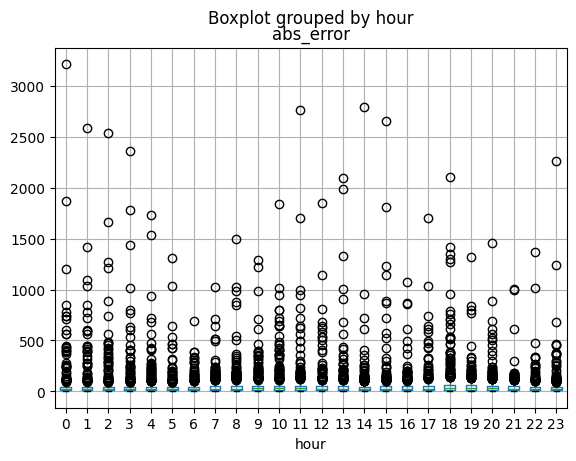

In [57]:
lasso_res['abs_error'] = np.abs(lasso_res['price_tgt'] - lasso_res['pred_eur'])
lasso_res.boxplot(column='abs_error', by='hour')
plt.show()

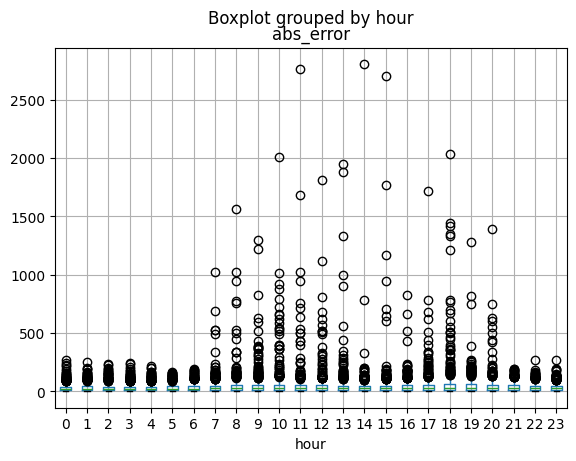

In [58]:
tree_res['abs_error'] = np.abs(tree_res['price_tgt'] - tree_res['pred_eur'])
tree_res.boxplot(column='abs_error', by='hour')
plt.show()

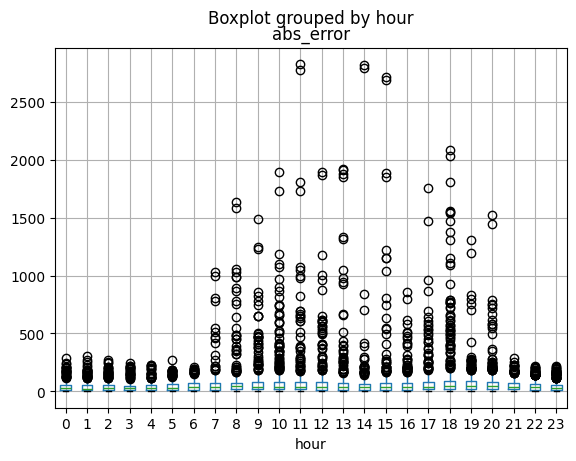

In [67]:
baseline_res['abs_error'] = np.abs(baseline_res['price_tgt'] - baseline_res['price_same_hour'])
baseline_res.boxplot(column='abs_error', by='hour')
plt.show()

In [59]:
lasso_res[lasso_res['abs_error'] > 500]

,date,hour,price_tgt,pred_eur,abs_error
4812,2021-07-20,12,704.47,84.705475,619.764525
5265,2021-08-08,9,1288.92,66.307043,1222.612957
5346,2021-08-11,18,893.05,101.950194,791.099806
5507,2021-08-18,11,839.90,119.935784,719.964216
7277,2021-10-31,5,15.73,-521.117318,536.847318
...,...,...,...,...,...
17297,2022-12-22,17,849.09,210.088172,639.001828
17394,2022-12-26,18,700.08,180.577399,519.502601
17436,2022-12-28,12,1366.87,221.605497,1145.264503
17443,2022-12-28,19,963.39,189.806942,773.583058


In [60]:
tree_res[tree_res['abs_error'] > 500]

,date,hour,price_tgt,pred_eur,abs_error
4812,2021-07-20,12,704.47,80.751731,623.718269
5265,2021-08-08,9,1288.92,63.919125,1225.000875
5346,2021-08-11,18,893.05,105.398408,787.651592
5507,2021-08-18,11,839.90,125.610818,714.289182
7546,2021-11-11,10,1267.22,250.354081,1016.865919
...,...,...,...,...,...
17294,2022-12-22,14,2969.36,162.414089,2806.945911
17297,2022-12-22,17,849.09,168.917346,680.172654
17436,2022-12-28,12,1366.87,248.633226,1118.236774
17443,2022-12-28,19,963.39,217.756726,745.633274


In [68]:
baseline_res[baseline_res['abs_error'] > 500]

,date,hour,price_tgt,price_same_hour,abs_error
4812,2021-07-20,12,704.47,99.67,604.80
4836,2021-07-21,12,106.45,704.47,598.02
5265,2021-08-08,9,1288.92,45.10,1243.82
5289,2021-08-09,9,55.04,1288.92,1233.88
5346,2021-08-11,18,893.05,101.65,791.40
...,...,...,...,...,...
17443,2022-12-28,19,963.39,208.52,754.87
17455,2022-12-29,7,1192.79,199.63,993.16
17460,2022-12-29,12,184.85,1366.87,1182.02
17467,2022-12-29,19,166.46,963.39,796.93


From the boxplot by different hours, the errors are mostly dominated by those large prediction errors. For lasso it could make largely errornous predictions in every hour, but for trees in the middle of the day it's more likely to have large predictive errors. And from the baseline we see that lasso is doing even worse than the baseline at the beginning/end of the day by creating even more large errors, the tree is simply doing a better than baseline in those parts. When we look at the rows where error is larger than 500, trees have about 2x less rows of >500 errors. 

In [69]:
lasso_neg_tgt = lasso_res[lasso_res['price_tgt'] < 0]
print('Lasso MAE on negative hours:', mean_absolute_error(lasso_neg_tgt['price_tgt'], lasso_neg_tgt['pred_eur']))
tree_neg_tgt = tree_res[tree_res['price_tgt'] < 0]
print('Tree MAE on negative hours:', mean_absolute_error(tree_neg_tgt['price_tgt'], tree_neg_tgt['pred_eur']))
baseline_neg_tgt = baseline_res[baseline_res['price_tgt'] < 0]
print('Baseline MAE on negative hours:', mean_absolute_error(baseline_neg_tgt['price_tgt'], baseline_neg_tgt['price_same_hour']))

Lasso MAE on negative hours: 223.95581637186876
Tree MAE on negative hours: 94.74023862366339
Baseline MAE on negative hours: 80.61668721109399


On those negative hours, baseline is doing the best among all three models. Lasso has a quite large MAE compared with the whole period, while the relationship for trees are modest.

In [62]:
m, tr, te = next(monthly_splits(df, start='2022-12-01', end='2022-12-01', train_months=3))
lasso = make_lasso().fit(df.loc[tr, features_lasso], df.loc[tr, 'adj_price_tgt'])

coef = pd.Series(lasso[-1].coef_, index=features_lasso)   # lasso[-1] = the Lasso step of the pipeline
print('intercept', lasso[-1].intercept_, '| zeroed:', (coef == 0).sum(), 'of', len(coef))
coef[coef != 0].sort_values(key=abs, ascending=False)

intercept -0.0009042645088030096 | zeroed: 24 of 45


resid_load                        0.514376
price_same_hour_tran              0.184008
change_resid_load                 0.102000
roll_forecast_error              -0.101987
scale_tgt                         0.071834
load_forecast_mw                  0.064909
daily_avg_price_tran              0.057408
d_5                              -0.050925
price_same_hour_last_week_tran    0.047350
d_0                               0.041968
d_6                              -0.031456
z_28d                            -0.025717
relative_resid_load               0.024964
h_18                              0.015834
d_2                               0.011746
h_20                              0.009716
h_17                              0.008055
h_7                               0.002029
h_19                              0.001785
d_3                              -0.001623
h_14                             -0.000729
dtype: float64

In [63]:
coefs = {}
for m, tr, te in monthly_splits(df, **split):
    fit = make_lasso().fit(df.loc[tr, features_lasso], df.loc[tr, 'adj_price_tgt'])
    coefs[m] = fit[-1].coef_
coefs = pd.DataFrame(coefs, index=features_lasso).T          # rows = refit month

pd.DataFrame({'median': coefs.median(),
              'share_nonzero': (coefs != 0).mean(),
              'share_positive': (coefs > 0).mean()}).loc[common + tran]

,median,share_nonzero,share_positive
z_28d,-0.000000,0.30,0.00
level_tgt,-0.136099,0.90,0.00
scale_tgt,0.000000,0.70,0.30
load_forecast_mw,0.059723,0.95,0.95
wind_forecast_mw,-0.000000,0.25,0.00
solar_forecast_mw,-0.014612,0.55,0.00
resid_load,0.570801,1.00,1.00
change_resid_load,0.073293,0.95,0.95
relative_resid_load,0.019667,0.65,0.65
roll_forecast_error,0.000020,0.75,0.50


In [66]:
for g, cols in groups.items():
    r = walk_forward(df, [col for col in features_tree if col not in cols], make_tree, **split)
    print(f'Features without group {g} generate MAE of {mean_absolute_error(r['price_tgt'], r['pred_eur'])}')

Features without group prices generate MAE of 49.85532374768371
Features without group fundamentals generate MAE of 55.798195851503706
Features without group calendar generate MAE of 43.11513867085913


From ablation test, we see that prices and fundamental features are actually pretty important in prediction, while the intraday shape doesn't matter a lot, partly because the fundamentals are already expressing part of the calendar effect.

In [70]:
lasso_res.describe()

,date,hour,price_tgt,pred_eur,abs_error
count,14640,14640.000000,14640.000000,14640.000000,14640.000000
mean,2022-03-01 11:59:59.999999744,11.500000,174.119401,155.850113,50.395551
min,2021-05-01 00:00:00,0.000000,-184.030000,-3329.202265,0.002410
25%,2021-09-30 00:00:00,5.750000,104.107500,93.258097,11.437881
50%,2022-03-01 12:00:00,11.500000,166.880000,176.348799,26.208267
75%,2022-08-01 00:00:00,17.250000,230.457500,232.914644,49.663078
max,2022-12-31 00:00:00,23.000000,3000.000000,732.146986,3215.982265
std,NaN,6.922423,134.109185,150.094134,124.816109


In [71]:
tree_res.describe()

,date,hour,price_tgt,pred_eur,abs_error
count,14640,14640.000000,14640.000000,14640.000000,14640.000000
mean,2022-03-01 11:59:59.999999744,11.500000,174.119401,169.922123,43.036019
min,2021-05-01 00:00:00,0.000000,-184.030000,-342.296865,0.009139
25%,2021-09-30 00:00:00,5.750000,104.107500,100.463014,11.222993
50%,2022-03-01 12:00:00,11.500000,166.880000,170.593115,24.954331
75%,2022-08-01 00:00:00,17.250000,230.457500,234.838950,49.250324
max,2022-12-31 00:00:00,23.000000,3000.000000,764.267536,2806.945911
std,NaN,6.922423,134.109185,95.518929,93.344530


From the descriptive statistics we see that the lasso predicts prices of -3329 at minimum, which is a quite insane number. 

In [74]:
pd.merge(df, lasso_res.loc[lasso_res['pred_eur'] < -1000, ['date', 'hour']], on=['date','hour'])['resid_load'].describe()

count       31.000000
mean    -23556.741935
std       9761.944868
min     -42128.000000
25%     -29566.000000
50%     -22082.000000
75%     -16644.500000
max      -6434.000000
Name: resid_load, dtype: float64

In [75]:
pd.merge(df, lasso_res[['date', 'hour']], on=['date','hour'])['resid_load'].describe()

count    14010.000000
mean     34273.552534
std      13697.156332
min     -42128.000000
25%      28450.250000
50%      36604.500000
75%      43353.000000
max      63906.000000
Name: resid_load, dtype: float64

For those data that predicts a very negative price, their resid_load feature is also quite negative compared with the whole period, combined with the lasso coefficient we used before, this kind of explains the negative magnitude of these predictions. Because linear relationships are assumed between price and resid_load in lasso, it is hard to avoid this issue. So instead of making further feature engineering to introduce nonlinear features in the lasso model, we tend to use tree model because first it already deals with the nonlinearity issues, second it generates predictions that are sane because it is doing some average of training labels in the leaf nodes.

### OOS test

In [ ]:
oos_split = dict(start='2023-01-01', end='2023-12-31', train_months=3)
lasso_oos = walk_forward(df, features_lasso, make_lasso, **oos_split)
tree_oos = walk_forward(df, features_tree, make_tree, **oos_split)

lasso_mae = mean_absolute_error(lasso_oos['price_tgt'], lasso_oos['pred_eur'])
tree_mae = mean_absolute_error(tree_oos['price_tgt'], tree_oos['pred_eur'])

baseline_oos = df.loc[lasso_oos.index, ['date', 'hour', 'price_tgt', 'price_same_hour']]
baseline_mae = mean_absolute_error(baseline_oos['price_tgt'], baseline_oos['price_same_hour'])

print("Lasso MAE (OOS walk forward) :", lasso_mae)
print("Tree MAE (OOS walk forward) :", tree_mae)
print("Baseline MAE (OOS walk forward):", baseline_mae)

Lasso MAE (OOS walk forward) : 33.33675788556458
Tree MAE (OOS walk forward) : 33.98684936765244
Baseline MAE (OOS walk forward): 55.34692078754579
